# Keeping Warm with Finite Elements
## The stationary heat equation in an L-shaped room with a tiled stove

*A self-contained, hands-on introduction to the finite element method (FEM) for first-semester graduate students with an engineering background.*

---

It is a winter evening, $0\,^\circ\mathrm{C}$ outside. You are sitting in an old apartment with an **L-shaped** living room. The walls were recently renovated with excellent insulation, but the old **single-glazed windows** were kept. Roughly in the middle of the room stands a traditional **tiled stove** ("Kachelofen") that releases $1.5\,$kW of heat. Some questions you might ask:

* Which parts of the room become comfortably warm, and where is it chilly?
* How much of the heat escapes through each of the two windows?
* What stove power would keep the room at an average of $21\,^\circ\mathrm{C}$?

In this notebook we answer these questions by solving the **stationary heat equation with a heat source** using the **finite element method**. We write every line of the solver ourselves, using only `numpy`, `scipy` and `matplotlib`. No black box.

### What you will learn

| Part | Topic | Key idea |
|---|-------|----------|
| 1–2 | Modelling | From energy conservation and Fourier's law to a boundary value problem with a heat source, Dirichlet and Neumann conditions; why FEM |
| 3 | Weak formulation | Why we multiply by test functions and integrate by parts, and why insulated walls then "come for free" |
| 4–6 | Galerkin method & P1 elements | Hat functions, meshes, element matrices, load vectors, assembly, sparse linear systems |
| 7 | Solution & engineering post-processing | Dirichlet conditions, heat flux, energy balance, heat loss per window from "reaction forces" |
| 8 | Verification | Method of manufactured solutions, convergence rates |
| 9 | Non-convex geometry & mixed boundary conditions | Singularities at corners and window edges, why uniform meshes struggle, and **adaptive** mesh refinement |

**Prerequisites:** multivariable calculus (gradient, divergence, Gauss' theorem), basic linear algebra, some Python. Experience with structural FEM helps, and we point out the analogies along the way.

**How to use this notebook:** run the cells from top to bottom (`Shift+Enter`). Boxes labelled **Try it yourself** invite you to change parameters and re-run. **Check your understanding** questions have hidden answers. Click to reveal them, but think first!

In [1]:
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.path import Path
from matplotlib.patches import Polygon
from matplotlib.colors import ListedColormap

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": False})
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__)

numpy 2.5.3


---
# Part 1 — The engineering problem and its mathematical model

## 1.1 The room

We look at the room from above (a **floor plan**). Lengths are in metres:

* The room is the L-shaped polygon with corners $(0,0)$, $(8,0)$, $(8,3)$, $(5,3)$, $(5,6)$, $(0,6)$. The missing upper-right block belongs to the neighbour's flat.
* The **stove** occupies the square $[3,4]\times[2,3]$, close to the centre of mass of the room. It releases heat into the room: in our model it is a **heat source**.
* There are two **windows**, each $2\,$m wide: one in the south wall ($y=0$, $1\le x\le 3$) and one in the east wall ($x=8$, $0.5\le y\le 2.5$).
* All **walls** are perfectly insulated: no heat flows through them.

Notice the corner at $(5,3)$. There the room turns "inwards": the interior angle is $270^\circ$. Such a domain is called **non-convex**, and this corner is a **re-entrant corner**. Together with the edges of the windows, it will play a starring role in Part 9.

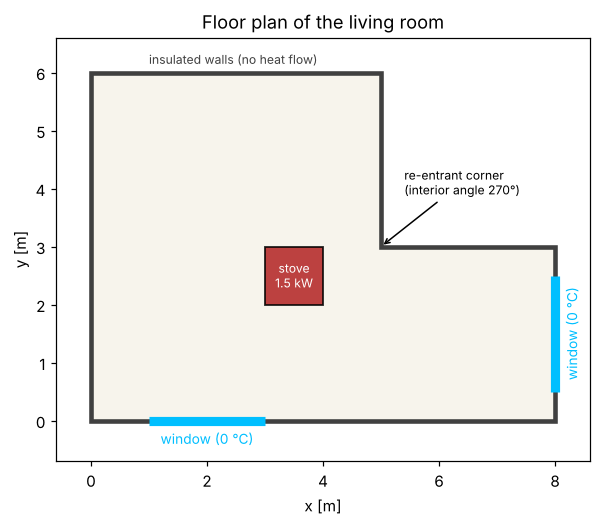

In [2]:
room    = np.array([(0, 0), (8, 0), (8, 3), (5, 3), (5, 6), (0, 6)], dtype=float)
stove   = np.array([(3, 2), (4, 2), (4, 3), (3, 3)], dtype=float)
windows = {"south": ((1, 0), (3, 0)), "east": ((8, 0.5), (8, 2.5))}

def draw_floor_plan(ax, annotate=True, fill=True):
    ax.add_patch(Polygon(room, closed=True, fc="#f7f4ec" if fill else "none", ec="0.25", lw=3, zorder=0))
    for (a, b) in windows.values():
        ax.plot(*zip(a, b), color="deepskyblue", lw=6, solid_capstyle="butt", zorder=3)
    ax.add_patch(Polygon(stove, closed=True, fc="firebrick", ec="k", alpha=0.85 if fill else 1.0,
                         fill=fill, lw=1.2, zorder=4))
    if annotate:
        ax.text(3.5, 2.5, "stove\n1.5 kW", color="w", ha="center", va="center", fontsize=8, zorder=5)
        ax.text(2.0, -0.4, "window (0 °C)", color="deepskyblue", ha="center", fontsize=9)
        ax.text(8.15, 1.5, "window (0 °C)", color="deepskyblue", rotation=90, va="center", fontsize=9)
        ax.text(1.0, 6.15, "insulated walls (no heat flow)", color="0.25", fontsize=8)
        ax.annotate("re-entrant corner\n(interior angle 270°)", xy=(5, 3), xytext=(5.4, 3.9),
                    arrowprops=dict(arrowstyle="->"), fontsize=8)
    ax.set_xlim(-0.6, 8.6); ax.set_ylim(-0.7, 6.6); ax.set_aspect("equal")
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")

fig, ax = plt.subplots(figsize=(6.5, 5))
draw_floor_plan(ax)
ax.set_title("Floor plan of the living room")
plt.show()

## 1.2 Physics: energy balance and Fourier's law

Let $T(x,y)$ be the temperature in $^\circ\mathrm{C}$ and $\mathbf q$ the **heat flux** in $\mathrm{W/m^2}$, i.e. the energy flowing per second through a unit area.

**Fourier's law** (heat flows from warm to cold, proportionally to the temperature gradient):
$$
\mathbf q = -k\,\nabla T ,
$$
where $k$ is the thermal conductivity in $\mathrm{W/(m\,K)}$.

**Energy conservation** in steady state: for every control volume $\omega$ in the room, the heat flowing out through its surface equals the heat produced inside. With a **heat source density** $f$ in $\mathrm{W/m^3}$,
$$
\int_{\partial\omega}\mathbf q\cdot\mathbf n\,ds = \int_\omega f\,dx
\quad\overset{\text{Gauss}}{\Longrightarrow}\quad
\int_\omega \big(\nabla\cdot\mathbf q - f\big)\,dx = 0 \ \ \text{for all }\omega
\quad\Longrightarrow\quad
\nabla\cdot\mathbf q = f .
$$
Inserting Fourier's law gives the **stationary heat equation with a source**:
$$
\boxed{\;-\nabla\cdot\big(k\,\nabla T\big) = f \quad\text{in } \Omega\;}
$$
Here $\Omega$ is the whole L-shaped room, including the stove. The source is the stove power spread evenly over the stove area $A_{\text{st}}$ and the room height $H$:
$$
f(x,y) = \begin{cases} \dfrac{P}{H\,A_{\text{st}}} & \text{in the stove region},\\[1ex] 0 & \text{elsewhere.}\end{cases}
$$
Note that $f$ **jumps** at the stove boundary. This is no problem for the finite element method, as we will see.

> **Modelling assumptions — be honest about them!**
> 1. **Stationary:** we look at the equilibrium after the stove has been burning for a long time.
> 2. **2D floor plan:** temperature does not vary with height, and floor and ceiling (heated flats above and below) are adiabatic. All fluxes in the 2D model are per metre of room height. Multiply by the room height $H = 2.6\,$m to get watts.
> 3. **Effective conductivity:** in a real room, heat is carried mostly by **moving air** (natural convection), not by molecular conduction. Still air has $k\approx0.026\,\mathrm{W/(m\,K)}$, which would give absurd results. We use an **effective** conductivity $k_{\text{eff}} = 10\,\mathrm{W/(m\,K)}$ that lumps the mixing by convection into a diffusion model, everywhere including the stove region. Such calibrated "eddy conductivities" are common in building physics. A CFD simulation would resolve the flow instead.
> 4. **Idealised boundaries:** the walls are perfect insulators, and the inner surface of a single-glazed window is at outside temperature. Real walls leak a little, and real windows have a finite heat transfer coefficient. Both refinements lead to *Robin* conditions (see the Exercises).
>
> The model is simple on purpose. It lets us focus on the *numerical method*, and it still gives plausible engineering numbers.

## 1.3 Boundary conditions — two different kinds

The boundary $\partial\Omega$ consists of two kinds of pieces:

| Boundary piece | Physics | Mathematical condition | Name |
|---|---|---|---|
| $\Gamma_D$: windows | inner glass surface at outside temperature | $T = T_{\text{out}} = 0\,^\circ$C | **Dirichlet** (essential) |
| $\Gamma_N$: walls | perfect insulation, no heat flow | $\mathbf q\cdot\mathbf n = -k\,\partial_n T = 0$ | **Neumann** (natural) |

Here $\partial_n T = \nabla T\cdot\mathbf n$ is the derivative in the direction of the outward unit normal $\mathbf n$, so $-k\partial_nT = \mathbf q\cdot\mathbf n$ is the heat flux leaving the room.

**The physical picture:** heat is produced in the stove, spreads through the room, cannot leave through the walls, and must therefore leave through the windows. In steady state, all $1.5\,$kW leave through the glass.

All parameters are collected in the next cell.

In [3]:
params = dict(
    k_eff   = 10.0,     # effective thermal conductivity of the room air   [W/(m K)]
    T_out   = 0.0,      # outside temperature = window temperature          [deg C]
    P_stove = 1500.0,   # heating power of the stove                        [W]
    H_room  = 2.6,      # room height                                       [m]
)
A_stove = 1.0           # stove footprint [3,4] x [2,3]                      [m^2]
f_stove = params["P_stove"] / (params["H_room"] * A_stove)   # source density [W/m^3]

def in_stove(x, y):
    return (3 < x) & (x < 4) & (2 < y) & (y < 3)

print(f"source density in the stove: f = {f_stove:.1f} W/m^3  "
      f"(= {f_stove * A_stove:.1f} W per metre of room height)")

source density in the stove: f = 576.9 W/m^3  (= 576.9 W per metre of room height)


<details>
<summary><b>Check your understanding</b> (click to reveal)</summary>

1. *Why is there no time derivative in our equation?* We look for the equilibrium state. The full heat equation $\rho c\,\partial_t T - \nabla\cdot(k\nabla T) = f$ reduces to ours when $\partial_t T = 0$.
2. *Check the units.* $\nabla\cdot(k\nabla T)$ has units $\frac{1}{\mathrm m}\cdot\frac{\mathrm W}{\mathrm{m\,K}}\cdot\frac{\mathrm K}{\mathrm m} = \mathrm{W/m^3}$, the same as $f$. ✓
3. *What would happen if both windows were closed, i.e. insulated like the walls?* Then no heat could leave the room, but the stove keeps producing it, so the temperature would rise forever: there is **no steady state**. Mathematically, integrating the equation over $\Omega$ gives $\int_\Omega f\,dx = -\int_{\partial\Omega}k\,\partial_nT\,ds$. With insulation everywhere the right-hand side is $0$, but the left-hand side is $P/H>0$, a contradiction. A Dirichlet part of the boundary, however small, makes the problem well-posed.
</details>

---
# Part 2 — Why finite elements?

You may know **finite differences**: put a grid on the domain and replace derivatives by difference quotients. For our room this quickly becomes painful:

* **Geometry:** real floor plans have slanted walls, round columns and bay windows. A Cartesian grid does not fit them.
* **Flux boundary conditions** like the insulated walls need special one-sided stencils.
* **Discontinuous data:** the source $f$ jumps at the stove boundary, and the boundary condition jumps from "fixed temperature" to "no flux" at the window edges.
* **Local resolution:** we will see that the temperature changes rapidly at some special points. Finite differences make it hard to refine *only there*.

The **finite element method** handles all of this:

1. It works on **unstructured triangulations** that fit any polygon.
2. It starts from an **integral (weak) form** of the equation, where flux conditions appear naturally and discontinuous sources are harmless.
3. Meshes can be **refined locally**, even automatically (Part 9).

It also comes with a rigorous **error theory**: we can *predict* how fast the error decreases, and even *estimate* it from the computed solution.

Structural engineers know FEM from beams, plates and solids. The heat equation is the simplest scalar relative of linear elasticity, so everything you learn here carries over:

| Heat conduction | Linear elasticity |
|---|---|
| temperature $T$ | displacement $\mathbf u$ |
| heat flux $\mathbf q = -k\nabla T$ | stress $\boldsymbol\sigma = \mathbb C\,\boldsymbol\varepsilon(\mathbf u)$ |
| conductivity $k$ | Young's modulus, Poisson's ratio |
| heat source $f$ | body force (e.g. gravity) |
| prescribed temperature (window, Dirichlet) | support (prescribed displacement) |
| insulated wall (zero flux, Neumann) | traction-free edge |
| heat flowing out through a window | support reaction force |
| imperfect insulation (Robin) | elastic spring support |

---
# Part 3 — The weak formulation

The heat equation asks for a lot: $T$ must be twice differentiable, and the equation must hold at **every point**. That is not even possible across the stove boundary, where $f$ jumps! The finite element method relaxes this. We only require the equation to hold **on average**, tested against many weight functions.

## 3.1 Derivation step by step

**Step 1 — multiply by a test function and integrate.** Take a smooth function $v$ (a "virtual temperature" or "weight") that **vanishes on the Dirichlet boundary** $\Gamma_D$, here the windows. Multiply the PDE by $v$ and integrate over $\Omega$:
$$
-\int_\Omega \nabla\cdot(k\nabla T)\; v\,dx = \int_\Omega f\,v\,dx .
$$

**Step 2 — integrate by parts** (Green's formula, the multidimensional version of $\int u'v = [uv]-\int uv'$):
$$
\int_\Omega k\nabla T\cdot\nabla v\,dx \;-\; \int_{\partial\Omega} k\,\partial_n T\; v\,ds = \int_\Omega f\,v\,dx .
$$
The second derivatives are gone. Only first derivatives of $T$ and $v$ remain.

**Step 3 — insert the boundary conditions.** Split $\partial\Omega = \Gamma_D\cup\Gamma_N$:
* on $\Gamma_D$ (windows): $v=0$, so this part vanishes. We never need to know the heat flux there!
* on $\Gamma_N$ (walls): $k\partial_nT = 0$, so this part vanishes too.

The whole boundary integral disappears.

## 3.2 The weak problem

> Find $T$ with $T = T_{\text{out}}$ on the windows such that
> $$
\underbrace{\int_\Omega k\nabla T\cdot\nabla v\,dx}_{=:\,a(T,v)}
\;=\;
\underbrace{\int_\Omega f\,v\,dx}_{=:\,\ell(v)}
\qquad\text{for all test functions } v \text{ with } v=0 \text{ on the windows} .
$$

Mathematicians look for $T$ in the Sobolev space $H^1(\Omega)$: square-integrable functions with square-integrable first derivatives. Kinks are allowed! That is exactly what our piecewise linear finite element functions will have. A jumping $f$ is no problem either: it only needs to be integrable against $v$.

## 3.3 Essential vs. natural boundary conditions — the key insight

* The **Dirichlet** condition (windows) must be built into the space of admissible functions. It is **essential**.
* The **Neumann** condition (walls) does not appear as a constraint at all. It is hidden in the boundary integral that vanished in Step 3, and it is satisfied automatically, approximately, by the solution. It is **natural**. Insulated walls need **no code at all**!

> **Engineering view:** $a(T,v)=\ell(v)$ is the **principle of virtual work** of heat conduction. For our symmetric problem it is equivalent to **minimising an energy**:
> $$
J(T) = \tfrac12 \int_\Omega k|\nabla T|^2\,dx - \int_\Omega f\,T\,dx \;\longrightarrow\; \min ,
$$
> just as an elastic structure under load minimises "strain energy minus work of the loads".

The **Lax–Milgram lemma** guarantees that the weak problem has exactly one solution. The key property is that $a(v,v) = \int k|\nabla v|^2 > 0$ for every $v\neq0$ that vanishes on the windows. That needs at least one window: with insulation everywhere, any constant $v$ would give $a(v,v)=0$. This is question 3 of Part 1 again, now in mathematical form.

---
# Part 4 — The Galerkin idea and linear (P1) finite elements

## 4.1 From infinitely many to finitely many unknowns

The weak problem has infinitely many test functions and an unknown in an infinite-dimensional space. **Galerkin's idea:** replace the space by a finite-dimensional subspace $V_h$ spanned by basis functions $\varphi_1,\dots,\varphi_N$, and write
$$
T_h(x) = \sum_{j=1}^N T_j\,\varphi_j(x).
$$
Testing with $v=\varphi_i$ for every $i$ gives $N$ equations for $N$ unknowns:
$$
\sum_{j=1}^N \underbrace{\int_\Omega k\nabla\varphi_j\cdot\nabla\varphi_i\,dx}_{K_{ij}}\; T_j = \underbrace{\int_\Omega f\,\varphi_i\,dx}_{F_i},
\qquad\text{i.e.}\qquad \mathbf K\,\mathbf T = \mathbf F .
$$
$\mathbf K$ is the **stiffness matrix**; the name comes from structural mechanics. $\mathbf F$ is the **load vector**, which here contains the stove's heat.

## 4.2 Hat functions

We cut $\Omega$ into triangles (a **mesh**). For every mesh node $x_j$, the **hat function** $\varphi_j$ is the continuous function that is linear on each triangle, equals $1$ at node $j$, and equals $0$ at all other nodes. Two consequences:

* $T_j = T_h(x_j)$: the unknowns are simply the **nodal temperatures**.
* $\varphi_j$ is nonzero only on the triangles touching node $j$. Hence $K_{ij}\neq 0$ only if nodes $i$ and $j$ share a triangle, and **$\mathbf K$ is sparse**.

Let us look at hat functions, first in 1D and then in 2D.

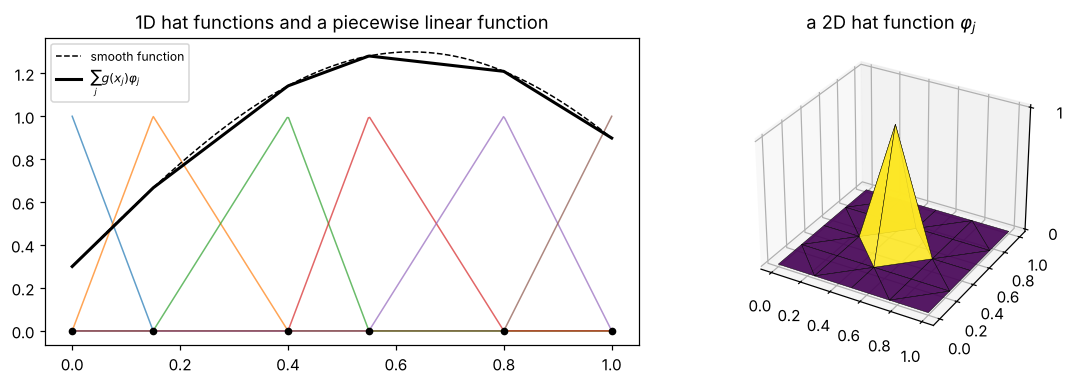

In [4]:
fig = plt.figure(figsize=(11, 3.6))

# --- 1D hat functions and a piecewise linear interpolant
ax = fig.add_subplot(1, 2, 1)
xn = np.array([0, 0.15, 0.4, 0.55, 0.8, 1.0])
xx = np.linspace(0, 1, 400)
for j in range(len(xn)):
    e = np.zeros(len(xn)); e[j] = 1
    ax.plot(xx, np.interp(xx, xn, e), lw=1, alpha=0.7)
g = lambda x: np.sin(2.5 * x) + 0.3
ax.plot(xx, g(xx), "k--", lw=1, label="smooth function")
ax.plot(xx, np.interp(xx, xn, g(xn)), "k", lw=2, label=r"$\sum_j g(x_j)\varphi_j$")
ax.plot(xn, 0 * xn, "ko", ms=4)
ax.set_title("1D hat functions and a piecewise linear function"); ax.legend(fontsize=8)

# --- one 2D hat function on a small mesh
ax = fig.add_subplot(1, 2, 2, projection="3d")
xs, ys = np.meshgrid(np.linspace(0, 1, 5), np.linspace(0, 1, 5))
pts = np.c_[xs.ravel(), ys.ravel()]
tri = mtri.Triangulation(pts[:, 0], pts[:, 1])
z = np.zeros(len(pts)); z[12] = 1.0                       # node in the middle
ax.plot_trisurf(tri, z, cmap="viridis", edgecolor="k", lw=0.3, alpha=0.9)
ax.set_title(r"a 2D hat function $\varphi_j$"); ax.view_init(30, -60)
ax.set_zticks([0, 1])
plt.tight_layout(); plt.show()

---
# Part 5 — The mesh

## 5.1 Data structures

A triangular mesh is stored in two arrays plus the boundary information:

* `nodes` — shape `(N, 2)`: the $x,y$ coordinates of node $j$ in row $j$.
* `elems` — shape `(M, 3)`: the three node numbers of each triangle (the **connectivity**).
* `bedges` — shape `(B, 2)`: the boundary edges, and `blabels` — whether each edge is a `"window"` or a `"wall"`.

Professional codes use mesh generators such as Gmsh or Triangle. To stay dependency-free, we write a small generator. It covers the bounding box with squares of side $h_0$, keeps the squares inside the room, and splits each square into two triangles. This works because all walls and windows lie on a $0.5\,$m grid.

The stove boundary also lies on grid lines. Every triangle is therefore either completely inside or completely outside the stove, and the source $f$ is **constant on every triangle**. Aligning the mesh with discontinuities of the data is good practice.

(The order of the vertices in each triangle matters for the refinement algorithm of Part 9: the first two vertices form the triangle's **refinement edge**, here the diagonal.)

In [5]:
def structured_mesh(polygon, h0, holes=()):
    # Triangulate a polygon (corners on a grid of spacing h0), optionally minus polygonal holes.
    polygon = np.asarray(polygon, float)
    domain = Path(polygon)
    hole_paths = [Path(np.asarray(h, float)) for h in holes]
    xmin, ymin = polygon.min(axis=0)
    xmax, ymax = polygon.max(axis=0)
    nx, ny = int(round((xmax - xmin) / h0)), int(round((ymax - ymin) / h0))
    node_id = -np.ones((nx + 1, ny + 1), dtype=int)       # grid point -> node number
    nodes, elems = [], []

    def nid(i, j):                                        # create nodes on demand
        if node_id[i, j] < 0:
            node_id[i, j] = len(nodes)
            nodes.append((xmin + i * h0, ymin + j * h0))
        return node_id[i, j]

    for i in range(nx):
        for j in range(ny):
            centre = (xmin + (i + 0.5) * h0, ymin + (j + 0.5) * h0)
            if not domain.contains_point(centre) or any(hp.contains_point(centre) for hp in hole_paths):
                continue                                  # square lies outside the domain
            p0, p1, p2, p3 = nid(i, j), nid(i + 1, j), nid(i + 1, j + 1), nid(i, j + 1)
            elems.append((p2, p0, p1))                    # two triangles; diagonal p2-p0
            elems.append((p0, p2, p3))                    # is listed first (refinement edge)
    return np.array(nodes), np.array(elems, dtype=int)


def boundary_edges(elems):
    # An edge is on the boundary if it belongs to exactly one triangle.
    local = np.array([[0, 1], [1, 2], [2, 0]])
    e = elems[:, local].reshape(-1, 2)
    _, inv, cnt = np.unique(np.sort(e, axis=1), axis=0, return_inverse=True, return_counts=True)
    return e[cnt[inv.ravel()] == 1]


def room_label(x, y, tol=1e-9):
    # Classify a boundary edge by its midpoint (x, y).
    if (abs(y) < tol and 1 < x < 3) or (abs(x - 8) < tol and 0.5 < y < 2.5):
        return "window"
    return "wall"


def label_edges(nodes, bedges, rule):
    mid = 0.5 * (nodes[bedges[:, 0]] + nodes[bedges[:, 1]])
    return np.array([rule(x, y) for x, y in mid])


nodes0, elems0 = structured_mesh(room, h0=0.5)
bedges0 = boundary_edges(elems0)
blabels0 = label_edges(nodes0, bedges0, room_label)
print(f"{len(nodes0)} nodes, {len(elems0)} triangles, {len(bedges0)} boundary edges")
print({str(lab): int((blabels0 == lab).sum()) for lab in np.unique(blabels0)})

185 nodes, 312 triangles, 56 boundary edges
{'wall': 48, 'window': 8}


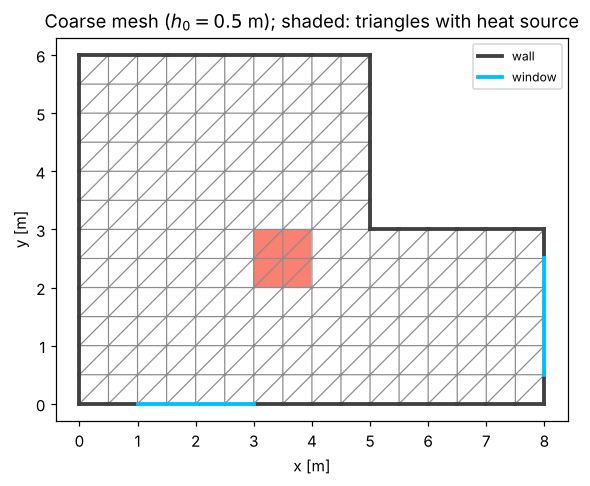

In [6]:
label_style = {"wall": "0.25", "window": "deepskyblue"}

def plot_mesh(ax, nodes, elems, bedges=None, blabels=None, lw=0.4):
    c = nodes[elems].mean(axis=1)
    src = in_stove(c[:, 0], c[:, 1])
    ax.tripcolor(mtri.Triangulation(nodes[:, 0], nodes[:, 1], elems), facecolors=src.astype(float),
                 cmap=ListedColormap(["white", "salmon"]), vmin=0, vmax=1, edgecolors="none")
    ax.triplot(mtri.Triangulation(nodes[:, 0], nodes[:, 1], elems), color="0.55", lw=lw)
    if bedges is not None:
        for lab, col in label_style.items():
            for p, q in bedges[blabels == lab]:
                ax.plot(*nodes[[p, q]].T, color=col, lw=2.5)
    ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")

fig, ax = plt.subplots(figsize=(6, 4.8))
plot_mesh(ax, nodes0, elems0, bedges0, blabels0, lw=0.8)
for lab, col in label_style.items():
    ax.plot([], [], color=col, lw=2.5, label=lab)
ax.legend(loc="upper right", fontsize=8)
ax.set_title(r"Coarse mesh ($h_0 = 0.5$ m); shaded: triangles with heat source")
plt.show()

## 5.2 Mesh refinement

Accuracy improves when the triangles get smaller. The simplest strategy is **uniform refinement**: split every triangle into four by connecting edge midpoints, which halves the mesh size $h$.

We implement this with **newest-vertex bisection**, which can also refine *locally*, a feature we need in Part 9. The function `refine_nvb` takes a list of **marked** triangles and bisects them. It also bisects neighbouring triangles as needed to avoid "hanging nodes", so the mesh stays **conforming**: neighbouring triangles always share complete edges. Uniform refinement simply marks all triangles.

You do not need to understand the details of `refine_nvb` now; we come back to it in Part 9.

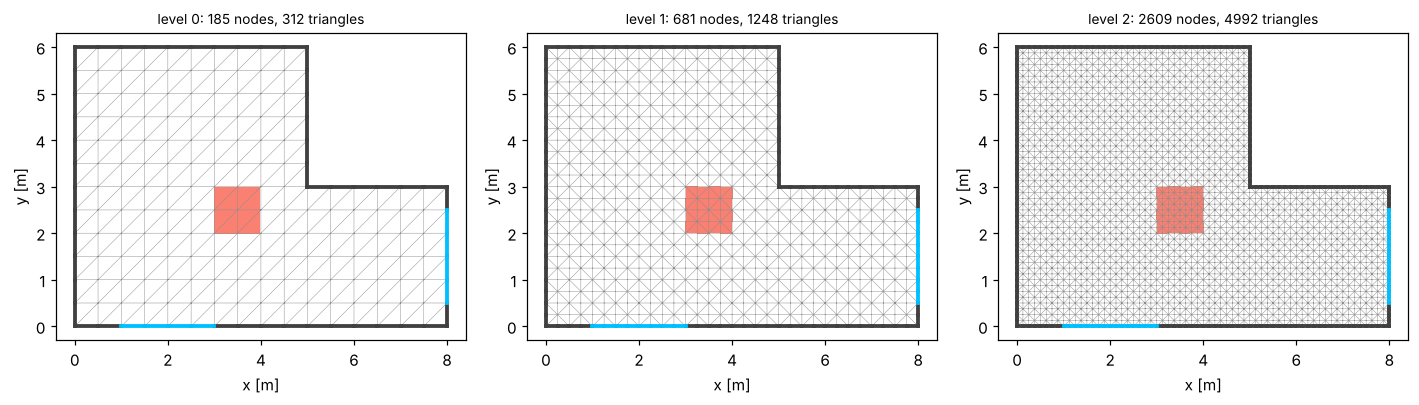

In [7]:
def refine_nvb(nodes, elems, bedges, blabels, marked):
    # Newest-vertex bisection; marked triangles are split into 4, neighbours are closed conformingly.
    # Element (a, b, c): refinement edge (a, b), 'newest vertex' c.
    nE = len(elems)
    local = np.array([[0, 1], [1, 2], [2, 0]])
    edges, inv = np.unique(np.sort(elems[:, local].reshape(-1, 2), axis=1), axis=0, return_inverse=True)
    el2ed = inv.ravel().reshape(nE, 3)                    # element -> its 3 edge numbers
    split = np.zeros(len(edges), dtype=bool)
    split[el2ed[marked].ravel()] = True                   # mark all edges of marked elements
    while True:                                           # closure: if any edge of a triangle is split,
        need = split[el2ed].any(axis=1) & ~split[el2ed[:, 0]]   # its refinement edge must be split too
        if not need.any():
            break
        split[el2ed[need, 0]] = True
    mid_id = -np.ones(len(edges), dtype=int)              # new midpoint nodes
    mid_id[split] = len(nodes) + np.arange(split.sum())
    nodes = np.vstack([nodes, 0.5 * (nodes[edges[split, 0]] + nodes[edges[split, 1]])])

    a, b, c = elems.T
    m0, m1, m2 = (mid_id[el2ed[:, k]] for k in range(3))
    flags = split[el2ed]
    patterns = {   # which edges are split  ->  children (always listed with refinement edge first)
        (0, 0, 0): lambda s: [np.c_[a[s], b[s], c[s]]],
        (1, 0, 0): lambda s: [np.c_[c[s], a[s], m0[s]], np.c_[b[s], c[s], m0[s]]],
        (1, 1, 0): lambda s: [np.c_[c[s], a[s], m0[s]], np.c_[m0[s], b[s], m1[s]], np.c_[c[s], m0[s], m1[s]]],
        (1, 0, 1): lambda s: [np.c_[m0[s], c[s], m2[s]], np.c_[a[s], m0[s], m2[s]], np.c_[b[s], c[s], m0[s]]],
        (1, 1, 1): lambda s: [np.c_[m0[s], c[s], m2[s]], np.c_[a[s], m0[s], m2[s]],
                              np.c_[m0[s], b[s], m1[s]], np.c_[c[s], m0[s], m1[s]]],
    }
    children = []
    for key, make in patterns.items():
        sel = np.all(flags == np.array(key, dtype=bool), axis=1)
        if sel.any():
            children += make(sel)
    elems = np.vstack(children)

    lookup = {tuple(e): i for i, e in enumerate(edges)}    # split boundary edges, keep labels
    new_b, new_l = [], []
    for (p, q), lab in zip(bedges, blabels):
        i = lookup[(min(p, q), max(p, q))]
        if split[i]:
            new_b += [(p, mid_id[i]), (mid_id[i], q)]; new_l += [lab, lab]
        else:
            new_b.append((p, q)); new_l.append(lab)
    return nodes, elems, np.array(new_b, dtype=int), np.array(new_l)


def refine_uniform(nodes, elems, bedges, blabels):
    return refine_nvb(nodes, elems, bedges, blabels, np.arange(len(elems)))


mesh = (nodes0, elems0, bedges0, blabels0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for level, ax in enumerate(axes):
    plot_mesh(ax, *mesh, lw=0.3)
    ax.set_title(f"level {level}: {len(mesh[0])} nodes, {len(mesh[1])} triangles", fontsize=9)
    mesh = refine_uniform(*mesh)
plt.tight_layout(); plt.show()

---
# Part 6 — Element computations: where the physics enters

Thanks to the hat functions, every integral in $a(\cdot,\cdot)$ and $\ell(\cdot)$ splits into a **sum over triangles**. On each triangle we compute a small **element matrix** and **element load vector** and then add them into the global system. This is the same strategy as in structural FEM.

## 6.1 Gradients of the hat functions

On a triangle $\tau$ with vertices $\mathbf x_0,\mathbf x_1,\mathbf x_2$, the three hat functions restricted to $\tau$ are the **barycentric coordinates** $\lambda_0,\lambda_1,\lambda_2$. They are linear, so their gradients are **constant** vectors:
$$
\nabla\lambda_i = \frac{1}{2|\tau|}\begin{pmatrix} y_{i+1}-y_{i+2}\\ x_{i+2}-x_{i+1}\end{pmatrix}\qquad(\text{indices mod } 3),
$$
where $2|\tau| = \det[\mathbf x_1-\mathbf x_0,\ \mathbf x_2-\mathbf x_0]$ (signed). Geometrically, $\nabla\lambda_i$ points from the edge opposite to vertex $i$ towards vertex $i$.

## 6.2 Element stiffness matrix

Since the gradients are constant, the integral is just "area times integrand":
$$
K^{\tau}_{ij} = \int_\tau k\,\nabla\lambda_j\cdot\nabla\lambda_i\,dx = k\,|\tau|\;\nabla\lambda_i\cdot\nabla\lambda_j, \qquad i,j = 0,1,2 .
$$

In [8]:
def gradients(nodes, elems):
    # Gradients of the 3 barycentric coordinates on every triangle -> shape (M, 3, 2), and areas (M,).
    P = nodes[elems]                                       # (M, 3, 2) vertex coordinates
    d1, d2 = P[:, 1] - P[:, 0], P[:, 2] - P[:, 0]
    det = d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]        # = 2 * signed area
    G = np.empty((len(elems), 3, 2))
    for i in range(3):
        j, l = (i + 1) % 3, (i + 2) % 3
        G[:, i, 0] = (P[:, j, 1] - P[:, l, 1]) / det
        G[:, i, 1] = (P[:, l, 0] - P[:, j, 0]) / det
    return G, 0.5 * np.abs(det)

# Test on the reference triangle (0,0), (1,0), (0,1):
G, area = gradients(np.array([[0., 0], [1, 0], [0, 1]]), np.array([[0, 1, 2]]))
print("area =", area[0])
print("gradients of lambda_0, lambda_1, lambda_2:\n", G[0])
K_ref = 1.0 * area[0] * G[0] @ G[0].T
print("element stiffness matrix (k = 1):\n", K_ref)
print("row sums:", K_ref.sum(axis=1))

area = 0.5
gradients of lambda_0, lambda_1, lambda_2:
 [[-1. -1.]
 [ 1.  0.]
 [ 0.  1.]]
element stiffness matrix (k = 1):
 [[ 1.  -0.5 -0.5]
 [-0.5  0.5  0. ]
 [-0.5  0.   0.5]]
row sums: [0. 0. 0.]


The result is the well-known matrix $\frac12\begin{pmatrix}2&-1&-1\\-1&1&0\\-1&0&1\end{pmatrix}$. Two properties are worth noticing:

* **Symmetric**: $K_{ij}=K_{ji}$, because $a(\cdot,\cdot)$ is symmetric. This is Maxwell–Betti reciprocity in disguise.
* **Rows sum to zero**: if all nodal temperatures are equal, $T_h$ is constant, and a constant temperature produces no heat flux. Physics shows up in the algebra!

## 6.3 Element load vector: the stove's heat

On a triangle where $f$ has the constant value $f_\tau$, we use $\int_\tau\lambda_i\,dx = |\tau|/3$:
$$
F^\tau_i = \int_\tau f\,\lambda_i\,dx = \frac{f_\tau\,|\tau|}{3}\begin{pmatrix}1\\1\\1\end{pmatrix}.
$$
Each vertex receives one third of the heat produced in the triangle. This is the analogue of distributing a body force to the nodes. For smooth, non-constant $f$ (needed in Part 8), we use a quadrature rule that evaluates $f$ at the three edge midpoints and is exact for quadratic integrands.

**And the insulated walls?** Their boundary integral vanished in the weak form, so there is **nothing to compute**. The natural boundary condition is built in.

## 6.4 Assembly

**Assembly** adds every element matrix into the global matrix at the rows and columns of its nodes. A first version with an explicit loop is the clearest way to see this:

In [9]:
def assemble_stiffness_loop(nodes, elems, kappa):
    # Clear but slow: one element at a time.
    N = len(nodes)
    K = sp.lil_matrix((N, N))
    G, area = gradients(nodes, elems)
    for t, tri in enumerate(elems):
        K_loc = kappa * area[t] * G[t] @ G[t].T            # 3x3 element matrix
        for a_loc in range(3):
            for b_loc in range(3):
                K[tri[a_loc], tri[b_loc]] += K_loc[a_loc, b_loc]
    return K.tocsr()

Python loops are slow. Production codes compute all element matrices at once and let `scipy.sparse` add up duplicate entries, using the coordinate (COO) format. The result is identical, which we check below. The load vector is assembled the same way with `np.add.at`.

In [10]:
def assemble_stiffness(nodes, elems, kappa):
    G, area = gradients(nodes, elems)
    K_loc = kappa * area[:, None, None] * np.einsum("tik,tjk->tij", G, G)   # all element matrices
    rows = np.repeat(elems, 3, axis=1).ravel()
    cols = np.tile(elems, (1, 3)).ravel()
    N = len(nodes)
    return sp.coo_matrix((K_loc.ravel(), (rows, cols)), shape=(N, N)).tocsr()  # duplicates are summed


def assemble_load(nodes, elems, f):
    # F_i = int f phi_i.  f: array of one value per triangle (piecewise constant source, exact),
    #                        or a function f(x, y) (edge-midpoint rule, exact for quadratics).
    _, area = gradients(nodes, elems)
    F = np.zeros(len(nodes))
    if callable(f):
        P = nodes[elems]
        mids = np.stack([(P[:, 0] + P[:, 1]) / 2, (P[:, 1] + P[:, 2]) / 2, (P[:, 2] + P[:, 0]) / 2], axis=1)
        fm = f(mids[..., 0], mids[..., 1])                              # (M, 3) values at midpoints
        lam = np.array([[.5, 0, .5], [.5, .5, 0], [0, .5, .5]])         # lambda_i at the midpoints
        np.add.at(F, elems, area[:, None] / 3 * fm @ lam.T)
    else:
        np.add.at(F, elems, (np.asarray(f) * area / 3)[:, None] * np.ones(3))
    return F


def stove_source(nodes, elems):
    # Source value per triangle: f_stove inside the stove, 0 elsewhere (decided by the centroid).
    c = nodes[elems].mean(axis=1)
    return np.where(in_stove(c[:, 0], c[:, 1]), f_stove, 0.0)


n1, e1, b1, l1 = refine_uniform(nodes0, elems0, bedges0, blabels0)
t0 = time.perf_counter(); K_slow = assemble_stiffness_loop(n1, e1, params["k_eff"]); t1 = time.perf_counter()
K_fast = assemble_stiffness(n1, e1, params["k_eff"]); t2 = time.perf_counter()
print(f"loop: {t1 - t0:.4f} s   vectorised: {t2 - t1:.4f} s   max difference: {abs(K_slow - K_fast).max():.2e}")
F1 = assemble_load(n1, e1, stove_source(n1, e1))
print(f"sum of the load vector = {F1.sum():.2f} W/m  (stove power per metre of height: {f_stove * A_stove:.2f} W/m)")

loop: 0.0465 s   vectorised: 0.0012 s   max difference: 0.00e+00
sum of the load vector = 576.92 W/m  (stove power per metre of height: 576.92 W/m)


The entries of the load vector add up to the total stove power per metre of height. That is because the hat functions add up to one everywhere: $\sum_i F_i = \int_\Omega f\sum_i\varphi_i\,dx = \int_\Omega f\,dx$. No heat is lost in the discretisation of the source.

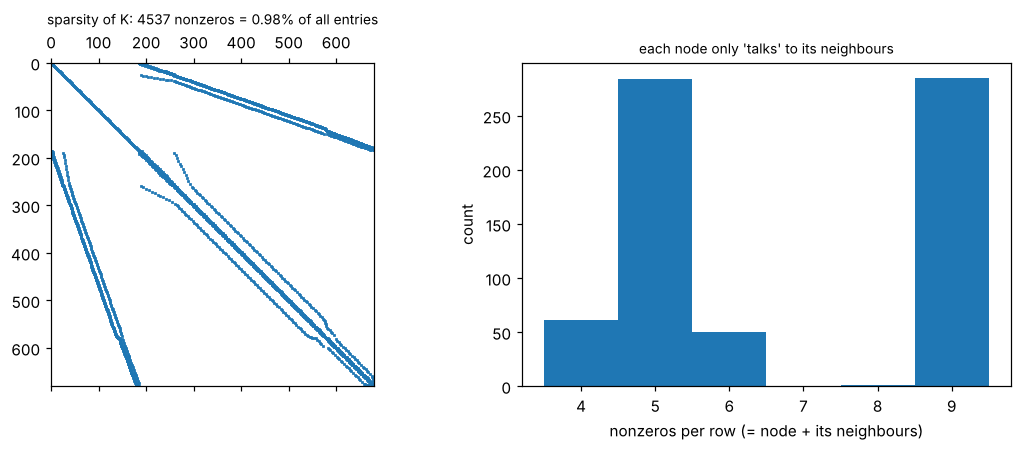

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].spy(K_fast, markersize=0.8)
axes[0].set_title(f"sparsity of K: {K_fast.nnz} nonzeros = {100 * K_fast.nnz / K_fast.shape[0]**2:.2f}% of all entries", fontsize=9)
deg = np.diff(K_fast.indptr)
axes[1].hist(deg, bins=np.arange(deg.min(), deg.max() + 2) - 0.5, color="tab:blue")
axes[1].set_xlabel("nonzeros per row (= node + its neighbours)"); axes[1].set_ylabel("count")
axes[1].set_title("each node only 'talks' to its neighbours", fontsize=9)
plt.tight_layout(); plt.show()

Only about 1% of the entries are nonzero even on this small mesh, and the fraction shrinks like $1/N$ under refinement. **Sparsity** is what makes FEM affordable: a mesh with a million nodes still has only about seven million nonzeros. Sparse direct solvers (as used below) or iterative solvers (conjugate gradients with multigrid) exploit it.

---
# Part 7 — Dirichlet conditions, solution and post-processing

## 7.1 Imposing the window temperature

The nodal values on the windows are **known**: $T_j = T_{\text{out}}$. Split the unknowns into **free** (f) and **Dirichlet** (D) nodes:
$$
\begin{pmatrix}\mathbf K_{ff} & \mathbf K_{fD}\\ \mathbf K_{Df} & \mathbf K_{DD}\end{pmatrix}
\begin{pmatrix}\mathbf T_f\\ \mathbf T_D\end{pmatrix}
=
\begin{pmatrix}\mathbf F_f\\ \mathbf F_D - \mathbf R_D\end{pmatrix}
\quad\Longrightarrow\quad
\boxed{\mathbf K_{ff}\,\mathbf T_f = \mathbf F_f - \mathbf K_{fD}\,\mathbf T_D}
$$
We solve only for the free nodes, and the known temperatures move to the right-hand side. With $T_{\text{out}}=0$ the extra term vanishes, but the code handles any prescribed value.

The Dirichlet rows contain an extra unknown $\mathbf R_D = \mathbf F_D - \mathbf K_{Df}\mathbf T_f - \mathbf K_{DD}\mathbf T_D$, the **reaction**. In mechanics these are the support forces; here they are the **heat flowing out of the room through the window nodes**. We will use them in Section 7.3.

In [12]:
def solve_dirichlet(K, F, dir_nodes, dir_values):
    N = K.shape[0]
    T = np.zeros(N)
    T[dir_nodes] = dir_values
    free = np.ones(N, dtype=bool); free[dir_nodes] = False
    rhs = F[free] - K[free][:, ~free] @ T[~free]
    T[free] = spla.spsolve(K[free][:, free].tocsc(), rhs)
    return T


def solve_room(nodes, elems, bedges, blabels, p=params):
    # Assemble and solve the room problem; return temperatures and reactions.
    K = assemble_stiffness(nodes, elems, p["k_eff"])
    F = assemble_load(nodes, elems, stove_source(nodes, elems))
    window_nodes = np.unique(bedges[blabels == "window"])
    T = solve_dirichlet(K, F, window_nodes, p["T_out"])
    reaction = F - K @ T              # zero at free nodes; heat leaving the room at window nodes
    return dict(T=T, window_nodes=window_nodes, reaction=reaction)


mesh = (nodes0, elems0, bedges0, blabels0)
for _ in range(3):
    mesh = refine_uniform(*mesh)
nodes, elems, bedges, blabels = mesh
t0 = time.perf_counter()
sol = solve_room(nodes, elems, bedges, blabels)
print(f"{len(nodes)} unknowns, solved in {time.perf_counter() - t0:.2f} s")
T = sol["T"]
_, area = gradients(nodes, elems)
T_mean = np.sum(area * T[elems].mean(axis=1)) / area.sum()
print(f"mean room temperature {T_mean:.1f} °C,  min {T.min():.1f} °C,  max {T.max():.1f} °C (inside the stove)")

10209 unknowns, solved in 0.09 s
mean room temperature 20.4 °C,  min 0.0 °C,  max 38.1 °C (inside the stove)


## 7.2 Visualising temperature and heat flow

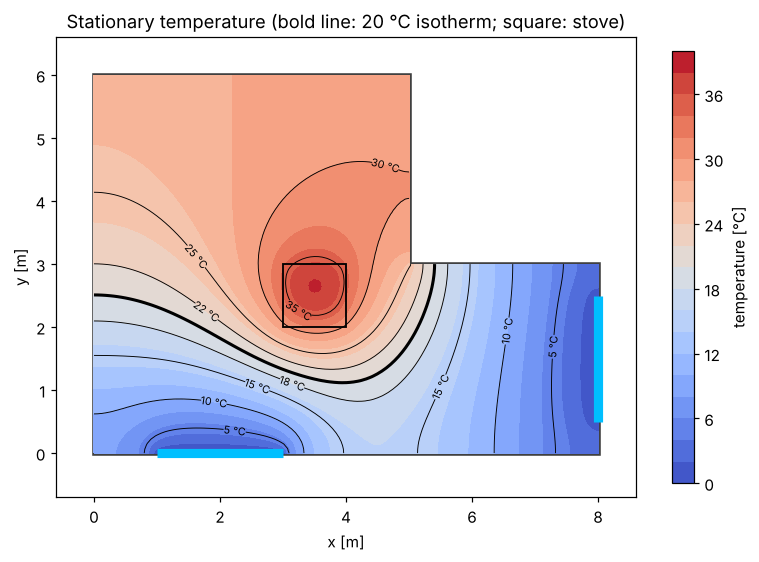

In [13]:
triang = mtri.Triangulation(nodes[:, 0], nodes[:, 1], elems)
fig, ax = plt.subplots(figsize=(8.5, 6))
cf = ax.tricontourf(triang, T, levels=np.arange(0, 40.1, 2), cmap="coolwarm")
cs = ax.tricontour(triang, T, levels=[5, 10, 15, 18, 22, 25, 30, 35], colors="k", linewidths=0.6)
ax.clabel(cs, fmt="%d °C", fontsize=7)
ax.tricontour(triang, T, levels=[20], colors="k", linewidths=2.0)
draw_floor_plan(ax, annotate=False, fill=False)
plt.colorbar(cf, ax=ax, label="temperature [°C]", shrink=0.85)
ax.set_title("Stationary temperature (bold line: 20 °C isotherm; square: stove)")
plt.show()

The warmest point is in the middle of the stove, and the temperature decreases towards the two windows, which are held at $0\,^\circ$C. Since the stove is closer to the south window, the south part of the room cools faster. The upper-left part of the room is far from both windows and stays warm, at $25$–$30\,^\circ$C.

Look at where the isotherms meet the **walls: always at right angles**. That is the zero-flux Neumann condition, $\partial_n T = 0$, which we never imposed explicitly: it comes out of the weak form by itself!

The **heat flux** $\mathbf q = -k\nabla T_h$ is constant on every triangle. A streamline plot shows where the heat goes:

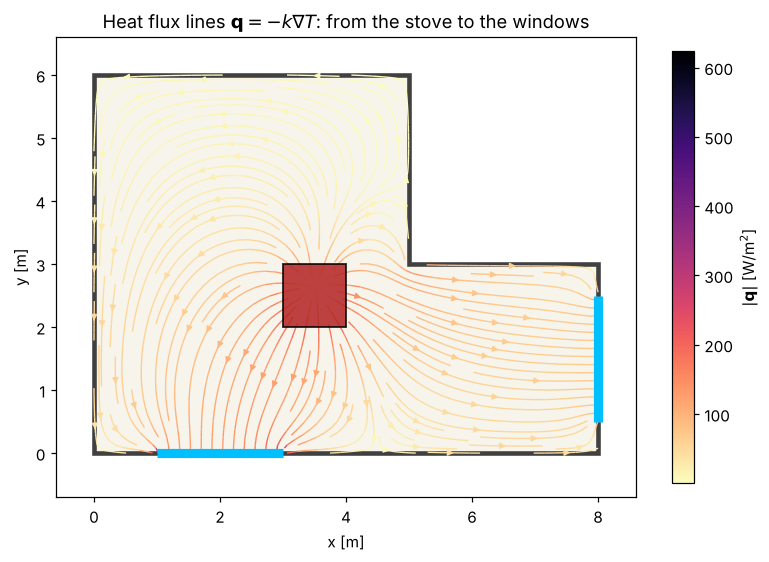

In [14]:
interp = mtri.LinearTriInterpolator(triang, T)
xg, yg = np.meshgrid(np.linspace(0, 8, 161), np.linspace(0, 6, 121))
dTdx, dTdy = interp.gradient(xg, yg)                       # masked outside the domain
qx, qy = -params["k_eff"] * dTdx, -params["k_eff"] * dTdy
qmag = np.hypot(qx, qy)

fig, ax = plt.subplots(figsize=(8.5, 6))
draw_floor_plan(ax, annotate=False)
strm = ax.streamplot(xg, yg, qx.filled(np.nan), qy.filled(np.nan), color=qmag.filled(np.nan),
                     cmap="magma_r", density=1.6, linewidth=0.9, arrowsize=0.8)
plt.colorbar(strm.lines, ax=ax, label=r"$|\mathbf{q}|$ [W/m$^2$]", shrink=0.85)
ax.set_title(r"Heat flux lines $\mathbf{q} = -k\nabla T$: from the stove to the windows")
plt.show()

Every flux line starts in the stove and ends in a window. No line crosses a wall, because the lines run **parallel** to the insulated walls. Two observations prepare us for Part 9:

1. The flux is strongly **concentrated at the edges of the windows**, where the boundary condition switches from "fixed temperature" to "no flux".
2. The flux lines bend sharply around the **re-entrant corner** $(5,3)$.

Keep these in mind!

## 7.3 Engineering post-processing: where does the energy go?

**Heat loss through the windows.** We never computed $\partial_nT$ on the windows. But the discrete equations at the Dirichlet nodes give it to us for free, as the **reactions** $\mathbf R_D = (\mathbf F - \mathbf K\mathbf T)_D$. This is the analogue of reading off support forces in structural analysis. Summing the reactions over the nodes of each window gives the heat that leaves through that window.

In steady state, **energy in (stove) = energy out (windows)**. Does our discrete solution respect this?

stove power (input):          1500.0 W
heat out, south window:       1017.7 W
heat out, east window:         482.3 W
balance (in - out):          2.2e-10 W


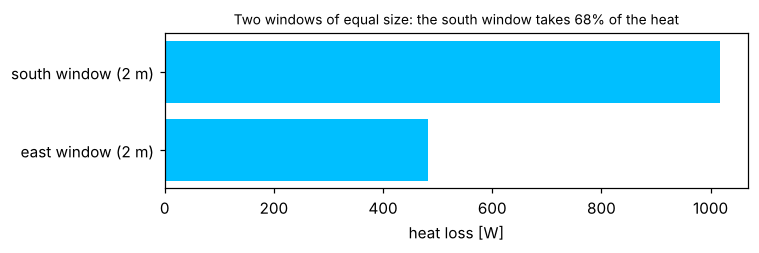

In [15]:
H = params["H_room"]
R = sol["reaction"]
wn = sol["window_nodes"]
south = wn[np.abs(nodes[wn, 1]) < 1e-9]
east = wn[np.abs(nodes[wn, 0] - 8) < 1e-9]
Q_south, Q_east = H * R[south].sum(), H * R[east].sum()
P_in = H * assemble_load(nodes, elems, stove_source(nodes, elems)).sum()
print(f"stove power (input):        {P_in:8.1f} W")
print(f"heat out, south window:     {Q_south:8.1f} W")
print(f"heat out, east window:      {Q_east:8.1f} W")
print(f"balance (in - out):         {P_in - Q_south - Q_east:8.1e} W")

fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(["east window (2 m)", "south window (2 m)"], [Q_east, Q_south], color="deepskyblue")
ax.set_xlabel("heat loss [W]")
ax.set_title(f"Two windows of equal size: the south window takes {100 * Q_south / P_in:.0f}% of the heat",
             fontsize=9)
plt.tight_layout(); plt.show()

The balance holds **to machine precision**, not merely approximately. This is no accident. Add up all equations of the linear system, i.e. test with $v = \sum_j\varphi_j \equiv 1$. The stiffness part cancels because its rows sum to zero, and what remains is exactly "window reactions = total source". The Galerkin method is **conservative** in this global sense.

Both windows have the same size, yet the south window carries about twice as much heat as the east window. It is closer to the stove, so the temperature gradient in front of it is steeper.

<details>
<summary><b>Check your understanding</b></summary>

*Why can we compute the heat loss through each window so accurately, even though the temperature gradient is only approximated by a constant on each triangle?* Because the reaction uses the weak form, i.e. integrals, instead of pointwise derivatives. Such "variationally consistent" flux evaluations converge faster than differentiating $T_h$ directly.
</details>

**Linearity pays off.** With $T_{\text{out}} = 0$ the temperature field is **proportional** to the stove power: doubling $P$ doubles $T$ everywhere. So we can answer "which power gives a mean temperature of $21\,^\circ$C?" without solving again:

In [16]:
T_target = 21.0
P_needed = params["P_stove"] * T_target / T_mean
print(f"current mean temperature: {T_mean:.2f} °C at P = {params['P_stove']:.0f} W")
print(f"power for a mean of {T_target:.0f} °C:  P = {P_needed:.0f} W")

current mean temperature: 20.40 °C at P = 1500 W
power for a mean of 21 °C:  P = 1544 W


> **Try it yourself:**
> 1. Move the stove next to the east window, e.g. to $[6,7]\times[1,2]$, by changing `stove` and `in_stove` (keep the corners on the $0.5\,$m grid). Re-run Parts 5–7. How does the split between the windows change, and why does the room get colder at the same power?
> 2. Make the south window twice as wide. How much more power is needed for a mean of $21\,^\circ$C?

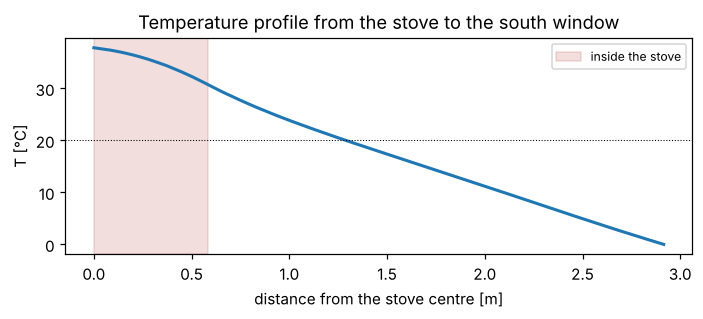

In [17]:
# A temperature profile: walking from the centre of the stove to the middle of the south window
s = np.linspace(0, 1, 300)
path = np.c_[3.5 - 1.5 * s, 2.5 - 2.5 * s]
prof = interp(path[:, 0], path[:, 1])
dist = s * np.hypot(1.5, 2.5)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(dist, prof, lw=2)
ax.axvspan(0, dist[np.argmax(~in_stove(path[:, 0], path[:, 1]))], color="firebrick", alpha=0.15,
           label="inside the stove")
ax.axhline(20, color="k", lw=0.7, ls=":")
ax.set_xlabel("distance from the stove centre [m]"); ax.set_ylabel("T [°C]"); ax.legend(fontsize=8)
ax.set_title("Temperature profile from the stove to the south window")
plt.tight_layout(); plt.show()

Inside the stove the profile is curved (concave), because heat is produced there: $-kT'' = f > 0$. Outside the stove there is no source, and in a 1D cut the profile would be a straight line. In 2D the heat spreads sideways, so the profile is still bent, but the curvature is not caused by a source.

---
# Part 8 — Verification: does the code solve the equations correctly?

Pretty pictures prove nothing. Before trusting a simulation, an engineer must **verify** the code ("are we solving the equations right?"). **Validation** ("are we solving the right equations?") is a separate question, answered by measurements.

The standard verification tool is the **method of manufactured solutions (MMS)**:

1. Pick any smooth function $u$, say $u(x,y) = \sin(\pi x/4)\cos(\pi y/6) + 0.1\,xy$.
2. Compute $f := -\Delta u$ analytically, then solve $-\Delta u_h = f$ with $u_h = u$ on the boundary, on the same room geometry.
3. Measure the error $u - u_h$ on finer and finer meshes.

**FEM theory predicts** for P1 elements and a smooth solution:
$$
\|u - u_h\|_{L^2} \le C\,h^2, \qquad \|\nabla(u-u_h)\|_{L^2} \le C\,h .
$$
Halving $h$ should therefore divide the $L^2$ error by $4$ and the gradient error by $2$. If our code has a bug, we will (almost certainly) see it in the rates.

For the error integrals we use a 7-point Gauss rule on each triangle.

In [18]:
# 7-point Gauss rule on triangles (degree 5): barycentric points and weights (relative to area)
QB = np.array([[1/3, 1/3, 1/3],
               [0.059715871789770, 0.470142064105115, 0.470142064105115],
               [0.470142064105115, 0.059715871789770, 0.470142064105115],
               [0.470142064105115, 0.470142064105115, 0.059715871789770],
               [0.797426985353087, 0.101286507323456, 0.101286507323456],
               [0.101286507323456, 0.797426985353087, 0.101286507323456],
               [0.101286507323456, 0.101286507323456, 0.797426985353087]])
QW = np.array([0.225] + [0.132394152788506] * 3 + [0.125939180544827] * 3)

def fem_errors(nodes, elems, u_h, u_exact, grad_exact):
    G, area = gradients(nodes, elems)
    X = np.einsum("qi,tid->tqd", QB, nodes[elems])                      # quadrature points
    uh_q = np.einsum("qi,ti->tq", QB, u_h[elems])
    grad_uh = np.einsum("tid,ti->td", G, u_h[elems])
    gx, gy = grad_exact(X[..., 0], X[..., 1])
    eL2 = np.sum(area[:, None] * QW * (u_exact(X[..., 0], X[..., 1]) - uh_q) ** 2)
    eH1 = np.sum(area[:, None] * QW * ((gx - grad_uh[:, None, 0]) ** 2 + (gy - grad_uh[:, None, 1]) ** 2))
    return np.sqrt(eL2), np.sqrt(eH1)

       h   nodes   L2 error  rate  grad error  rate
  1.0000      54   3.40e-01          1.05e+00      
  0.5000     185   7.22e-02  2.23    5.02e-01  1.06
  0.2500     681   1.80e-02  2.00    2.51e-01  1.00
  0.1250    2609   4.50e-03  2.00    1.25e-01  1.00
  0.0625   10209   1.12e-03  2.00    6.27e-02  1.00
  0.0312   40385   2.80e-04  2.00    3.13e-02  1.00


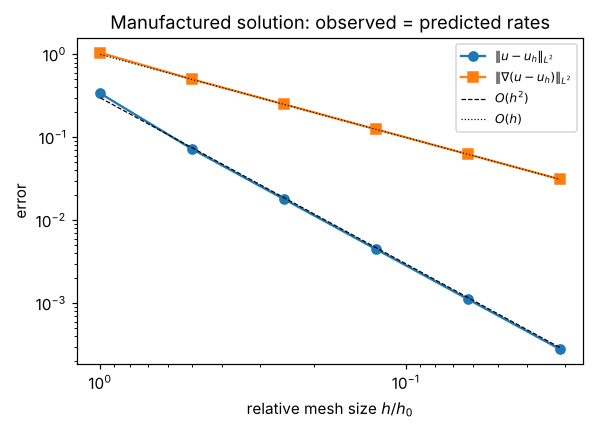

In [19]:
u_mms = lambda x, y: np.sin(np.pi * x / 4) * np.cos(np.pi * y / 6) + 0.1 * x * y
grad_mms = lambda x, y: (np.pi / 4 * np.cos(np.pi * x / 4) * np.cos(np.pi * y / 6) + 0.1 * y,
                         -np.pi / 6 * np.sin(np.pi * x / 4) * np.sin(np.pi * y / 6) + 0.1 * x)
f_mms = lambda x, y: ((np.pi / 4) ** 2 + (np.pi / 6) ** 2) * np.sin(np.pi * x / 4) * np.cos(np.pi * y / 6)

n_, e_ = structured_mesh(room, 1.0)
b_ = boundary_edges(e_); l_ = np.array(["D"] * len(b_))
rows = []
for level in range(6):
    K = assemble_stiffness(n_, e_, 1.0)
    F = assemble_load(n_, e_, f_mms)
    bn = np.unique(b_)
    u_h = solve_dirichlet(K, F, bn, u_mms(n_[bn, 0], n_[bn, 1]))
    eL2, eH1 = fem_errors(n_, e_, u_h, u_mms, grad_mms)
    rows.append((2.0 ** -level, len(n_), eL2, eH1))
    n_, e_, b_, l_ = refine_uniform(n_, e_, b_, l_)

print(f"{'h':>8} {'nodes':>7} {'L2 error':>10} {'rate':>5} {'grad error':>11} {'rate':>5}")
for i, (h, N, a, b) in enumerate(rows):
    ra = "" if i == 0 else f"{np.log2(rows[i-1][2] / a):5.2f}"
    rb = "" if i == 0 else f"{np.log2(rows[i-1][3] / b):5.2f}"
    print(f"{h:8.4f} {N:7d} {a:10.2e} {ra:>5} {b:11.2e} {rb:>5}")

hs = np.array([r[0] for r in rows])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(hs, [r[2] for r in rows], "o-", label=r"$\|u-u_h\|_{L^2}$")
ax.loglog(hs, [r[3] for r in rows], "s-", label=r"$\|\nabla(u-u_h)\|_{L^2}$")
ax.loglog(hs, 0.3 * hs ** 2, "k--", lw=0.8, label=r"$O(h^2)$")
ax.loglog(hs, 1.0 * hs, "k:", lw=0.8, label=r"$O(h)$")
ax.set_xlabel(r"relative mesh size $h/h_0$"); ax.set_ylabel("error"); ax.legend(fontsize=8)
ax.set_title("Manufactured solution: observed = predicted rates"); ax.invert_xaxis()
plt.tight_layout(); plt.show()

The observed rates are exactly $2$ and $1$, so the implementation is verified. Rates are a very sensitive test: a wrong sign in a single matrix entry would typically destroy them.

---
# Part 9 — Non-convex room and mixed boundary conditions: singularities and adaptive meshes

## 9.1 Something strange happens at corners and window edges

Let us look at the largest heat flux near three kinds of special points while we refine the mesh repeatedly: the re-entrant corner $(5,3)$, the four window edges, and the four corners of the stove. If the flux were a nice smooth function, its maximum would converge to a finite value.

In [20]:
window_ends = [(1, 0), (3, 0), (8, 0.5), (8, 2.5)]
near = lambda c, pts, rad: np.min([np.hypot(c[:, 0] - x, c[:, 1] - y) for x, y in pts], axis=0) < rad

mesh = (nodes0, elems0, bedges0, blabels0)
prev = None
print(f"{'nodes':>7} {'re-entrant corner':>18} {'window edges':>14} {'stove corners':>14}")
for level in range(6):
    n_, e_, b_, l_ = mesh
    s_ = solve_room(*mesh)
    G, _ = gradients(n_, e_)
    q = params["k_eff"] * np.linalg.norm(np.einsum("tid,ti->td", G, s_["T"][e_]), axis=1)
    c = n_[e_].mean(axis=1)
    vals = (q[near(c, [(5, 3)], 0.6)].max(), q[near(c, window_ends, 0.6)].max(), q[near(c, stove, 0.3)].max())
    growth = "" if prev is None else "   growth factors: " + "  ".join(f"{v / p:.2f}" for v, p in zip(vals, prev))
    print(f"{len(n_):7d} {vals[0]:18.1f} {vals[1]:14.1f} {vals[2]:14.1f}{growth}")
    prev = vals
    if level < 5:
        mesh = refine_uniform(*mesh)

  nodes  re-entrant corner   window edges  stove corners
    185              127.4          198.4          150.0
    681              144.4          297.9          186.2   growth factors: 1.13  1.50  1.24
   2609              175.4          434.2          193.0   growth factors: 1.21  1.46  1.04
  10209              214.7          623.5          197.7   growth factors: 1.22  1.44  1.02


  40385              265.0          888.6          200.3   growth factors: 1.23  1.43  1.01


 160641              329.3         1261.5          201.8   growth factors: 1.24  1.42  1.01


Three different behaviours appear:

* At the **stove corners** the maximal flux **converges**, to about $200\,\mathrm{W/m^2}$. Nothing special happens there.
* At the **re-entrant corner** it keeps growing, by a factor of about $1.25$ per refinement.
* At the **window edges** it keeps growing even faster, by a factor of about $1.41 \approx \sqrt2$ per refinement.

**This is not a bug.** The exact solution is **singular** at these points: its gradient is infinite there. Here is why, and where the factors $2^{1/3}\approx1.26$ and $2^{1/2}\approx1.41$ come from.

### Singularities in a nutshell

Place polar coordinates $(r,\theta)$ at a boundary point where the boundary has an interior angle $\omega$. Near that point, separation of variables shows that solutions of $-\Delta T = f$ behave like
$$
T(r,\theta) \approx T_0 + c\, r^{\beta}\,\Phi(\theta) + (\text{smoother terms})
\qquad\Longrightarrow\qquad
|\nabla T| \sim r^{\beta - 1},
$$
where the exponent $\beta$ depends on the angle **and on the boundary conditions** on the two sides:

| Situation | Exponent $\beta$ | Our room | $\beta$ | Flux |
|---|---|---|---|---|
| same type of condition on both sides (here: two insulated walls) | $\pi/\omega$ | re-entrant corner, $\omega = 270^\circ$ | $2/3$ | $\sim r^{-1/3}\to\infty$ |
| condition changes type (Dirichlet $\to$ Neumann) | $\pi/(2\omega)$ | window edge, straight wall, $\omega = 180^\circ$ | $1/2$ | $\sim r^{-1/2}\to\infty$ |
| convex corner, same condition | $\pi/\omega > 1$ | e.g. $(0,0)$ with insulated walls, $\omega = 90^\circ$ | $2$ | bounded |
| interior point where only $f$ jumps | — | stove corners | — | bounded |

On a mesh of size $h$, the largest computed flux sits in the triangle at the singular point, at distance $r\sim h$, so it behaves like $h^{\beta-1}$. Halving $h$ multiplies it by $2^{1-\beta}$: by $2^{1/3}\approx1.26$ at the re-entrant corner and by $2^{1/2}\approx1.41$ at the window edges. That is exactly what the table above shows.

**Physically**, sharp corners and abrupt jumps in the boundary condition are idealisations. A real wall corner is slightly rounded, and the glass is gradually connected to the frame, so the flux there is large but finite. The *energy* stays finite anyway, because $\int|\nabla T|^2$ converges: $\int_0 r^{2\beta-2}\,r\,dr<\infty$ for $\beta>0$. Engineers know the same phenomenon from **stress concentrations** at re-entrant corners, crack tips, and the edges of clamped supports.

**Numerically**, singularities are bad news for uniform meshes. The error is dominated by tiny regions around the singular points, and the convergence rate drops.

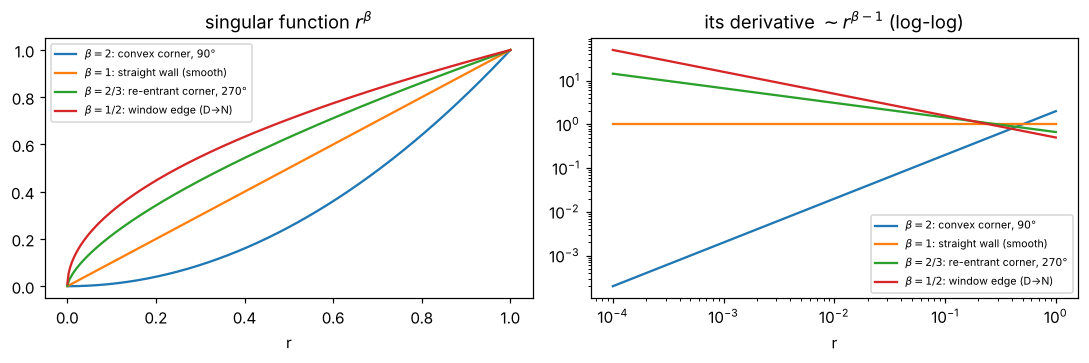

In [21]:
r = np.linspace(1e-4, 1, 400)
cases = [(2.0, r"$\beta=2$: convex corner, $90°$"), (1.0, r"$\beta=1$: straight wall (smooth)"),
         (2 / 3, r"$\beta=2/3$: re-entrant corner, $270°$"), (0.5, r"$\beta=1/2$: window edge (D→N)")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for beta, lab in cases:
    axes[0].plot(r, r ** beta, label=lab)
    axes[1].loglog(r, beta * r ** (beta - 1), label=lab)
axes[0].set_title(r"singular function $r^{\beta}$"); axes[0].set_xlabel("r")
axes[1].set_title(r"its derivative $\sim r^{\beta - 1}$ (log-log)"); axes[1].set_xlabel("r")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9.2 A benchmark with known exact solution

To measure the effect on the *error* precisely, we take the classic **L-shaped domain** $\Omega = (-1,1)^2\setminus[0,1]\times[-1,0]$, the mathematicians' version of our room. The function
$$
u(r,\theta) = r^{2/3}\sin\!\big(\tfrac{2}{3}\theta\big),\qquad 0\le\theta\le\tfrac{3\pi}{2},
$$
solves $-\Delta u = 0$ and vanishes on the two edges meeting at the re-entrant corner. We use it as Dirichlet data and compare $u_h$ with $u$.

With $N$ unknowns, the mesh size is $h\sim N^{-1/2}$. For smooth solutions the energy error behaves like $h\sim N^{-1/2}$. For the singular solution on uniform meshes theory predicts only $h^{2/3}\sim N^{-1/3}$.

In [22]:
L_shape = np.array([(-1, -1), (0, -1), (0, 0), (1, 0), (1, 1), (-1, 1)], dtype=float)

def polar(x, y):
    return np.hypot(x, y), np.mod(np.arctan2(y, x), 2 * np.pi)

def u_sing(x, y):
    r, th = polar(x, y)
    return r ** (2 / 3) * np.sin(2 * th / 3)

def grad_sing(x, y):
    r, th = polar(x, y); r = np.maximum(r, 1e-300)
    ur, ut = 2 / 3 * r ** (-1 / 3) * np.sin(2 * th / 3), 2 / 3 * r ** (-1 / 3) * np.cos(2 * th / 3)
    return ur * np.cos(th) - ut * np.sin(th), ur * np.sin(th) + ut * np.cos(th)

def solve_L(nodes, elems, bedges):
    K = assemble_stiffness(nodes, elems, 1.0)
    bn = np.unique(bedges)
    return solve_dirichlet(K, np.zeros(len(nodes)), bn, u_sing(nodes[bn, 0], nodes[bn, 1]))

nL, eL = structured_mesh(L_shape, 0.5)
bL = boundary_edges(eL); lL = np.array(["D"] * len(bL))
uniform_L = []
mesh = (nL, eL, bL, lL)
for level in range(6):
    u_h = solve_L(mesh[0], mesh[1], mesh[2])
    uniform_L.append((len(mesh[0]), fem_errors(mesh[0], mesh[1], u_h, u_sing, grad_sing)[1]))
    mesh = refine_uniform(*mesh)
for (N0, e0), (N1, e1_) in zip(uniform_L[:-1], uniform_L[1:]):
    print(f"N = {N1:6d}   energy error = {e1_:.3e}   rate in N: {np.log(e0 / e1_) / np.log(N1 / N0):.3f}")

N =     65   energy error = 1.845e-01   rate in N: 0.387
N =    225   energy error = 1.188e-01   rate in N: 0.354
N =    833   energy error = 7.595e-02   rate in N: 0.342
N =   3201   energy error = 4.830e-02   rate in N: 0.336
N =  12545   energy error = 3.061e-02   rate in N: 0.334


The rate is $\approx 1/3$ instead of $1/2$, as predicted. In practice this is a disaster. To halve the error we need $2^3 = 8$ times more unknowns instead of $2^2 = 4$. For the window-edge singularity ($\beta = 1/2$) it is even worse, and in 3D things get worse still.

The cure is obvious once you see the cause: **use small triangles near the singular points and large ones elsewhere.** But where exactly, and how small? In a real application we do not know the exact solution. The answer is **adaptivity**.

## 9.3 Adaptive finite elements: let the computation decide

Adaptive FEM repeats a simple loop:
$$
\boxed{\texttt{SOLVE}}\;\longrightarrow\;\boxed{\texttt{ESTIMATE}}\;\longrightarrow\;\boxed{\texttt{MARK}}\;\longrightarrow\;\boxed{\texttt{REFINE}}\;\longrightarrow\;\texttt{SOLVE}\;\dots
$$

**ESTIMATE — an a posteriori error indicator with an engineering meaning.** Every term measures a local violation of energy conservation by the discrete solution:

* **Inside a triangle**, $T_h$ is linear, so the discrete flux has zero divergence. Any heat produced there, $f\neq0$, cannot be balanced inside the triangle.
* **Across an edge**, the exact normal flux is continuous: what leaves one triangle enters the next. The discrete flux $-k\nabla T_h$ is constant per triangle and **jumps** across edges.
* **On an insulated wall**, the exact normal flux is zero, but the discrete one is not exactly zero.

The **residual error indicator** collects these defects for each triangle $\tau$:
$$
\eta_\tau^2 = h_\tau^2\,\|f\|_{L^2(\tau)}^2
+ \frac12\sum_{E\subset\partial\tau\ \text{interior}} h_E\,\big\|[\![k\,\partial_n T_h]\!]\big\|_{L^2(E)}^2
+ \sum_{E\subset\partial\tau\cap\Gamma_N} h_E\,\big\|k\,\partial_n T_h\big\|_{L^2(E)}^2 .
$$
Theory guarantees $C_1\,\eta \le \|\nabla(T-T_h)\| \le C_2\,\eta$ with $\eta^2=\sum_\tau\eta_\tau^2$, up to small data-oscillation terms. The computable $\eta$ tells us how large the error is and where it lives.

**MARK — Dörfler marking.** Mark the smallest set of triangles that together carry at least a fraction $\theta$ (here $50\%$) of the total $\eta^2$.

**REFINE — newest-vertex bisection.** Each triangle has a designated refinement edge, the one opposite its "newest vertex". Bisection cuts it at the midpoint, and the new node becomes the newest vertex of both children. Neighbours are bisected as needed to avoid hanging nodes. This is the closure loop in `refine_nvb`. The algorithm guarantees that triangles never degenerate, no matter how often we refine.

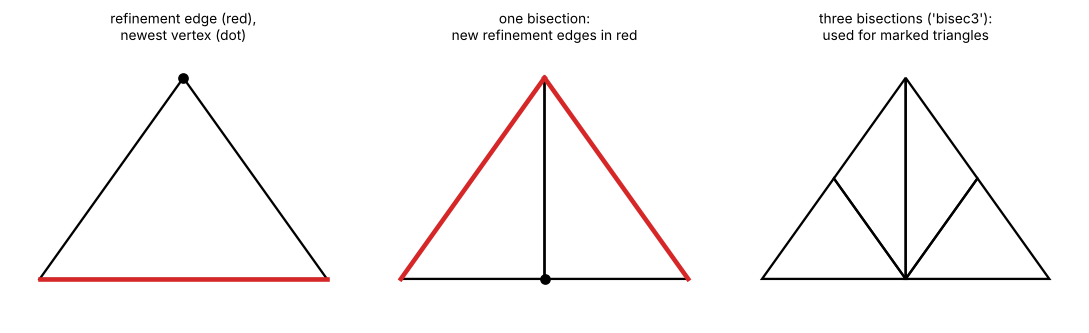

In [23]:
# Visualising newest-vertex bisection on a single triangle
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
A, B, C = np.array([0., 0]), np.array([2., 0]), np.array([1., 1.4])
def tri(ax, P, **kw):
    ax.add_patch(Polygon(P, closed=True, fill=False, **kw))
for ax in axes:
    ax.set_xlim(-0.2, 2.2); ax.set_ylim(-0.3, 1.6); ax.set_aspect("equal"); ax.axis("off")
tri(axes[0], [A, B, C], lw=1.5)
axes[0].plot(*zip(A, B), color="tab:red", lw=3); axes[0].plot(*C, "ko")
axes[0].set_title("refinement edge (red),\nnewest vertex (dot)", fontsize=9)
M0 = (A + B) / 2
for P in ([C, A, M0], [B, C, M0]):
    tri(axes[1], P, lw=1.5)
axes[1].plot(*zip(C, A), color="tab:red", lw=3); axes[1].plot(*zip(B, C), color="tab:red", lw=3)
axes[1].plot(*M0, "ko"); axes[1].set_title("one bisection:\nnew refinement edges in red", fontsize=9)
M1, M2 = (B + C) / 2, (C + A) / 2
for P in ([M0, C, M2], [A, M0, M2], [M0, B, M1], [C, M0, M1]):
    tri(axes[2], P, lw=1.5)
axes[2].set_title("three bisections ('bisec3'):\nused for marked triangles", fontsize=9)
plt.tight_layout(); plt.show()

In [24]:
def error_indicator(nodes, elems, T, kappa, bedges, kind, f_elem=None):
    # Residual indicator eta_tau^2 for P1. kind per boundary edge: 'D' (Dirichlet) or 'N' (Neumann).
    # f_elem: source value per triangle (piecewise constant), or None for f = 0.
    nE = len(elems)
    G, area = gradients(nodes, elems)
    grad = np.einsum("tid,ti->td", G, T[elems])            # constant gradient per triangle
    eta2 = np.zeros(nE)
    if f_elem is not None:                                  # (0) element residual h^2 ||f||^2
        eta2 += 2 * area * area * f_elem ** 2               #     with h_tau^2 ~ 2|tau|
    local = np.array([[0, 1], [1, 2], [2, 0]])
    edges, inv = np.unique(np.sort(elems[:, local].reshape(-1, 2), axis=1), axis=0, return_inverse=True)
    inv = inv.ravel(); owner = np.repeat(np.arange(nE), 3)
    order = np.argsort(inv, kind="stable"); inv_s, own_s = inv[order], owner[order]
    start = np.flatnonzero(np.r_[True, inv_s[1:] != inv_s[:-1]])
    count = np.diff(np.r_[start, len(inv_s)])
    t1 = own_s[start]                                       # first triangle of each edge
    t2 = np.where(count == 2, own_s[np.minimum(start + 1, len(own_s) - 1)], -1)
    tang = nodes[edges[:, 1]] - nodes[edges[:, 0]]
    length = np.linalg.norm(tang, axis=1)
    normal = np.c_[tang[:, 1], -tang[:, 0]] / length[:, None]
    # (1) flux jumps across interior edges
    i = np.flatnonzero(count == 2)
    jump = kappa * np.einsum("ed,ed->e", grad[t1[i]] - grad[t2[i]], normal[i])
    np.add.at(eta2, t1[i], 0.5 * length[i] ** 2 * jump ** 2)
    np.add.at(eta2, t2[i], 0.5 * length[i] ** 2 * jump ** 2)
    # (2) normal flux on Neumann (insulated) edges should be zero
    lookup = {tuple(e): j for j, e in enumerate(edges)}
    for b, (p, q) in enumerate(bedges):
        if kind[b] == "D":
            continue
        j = lookup[(min(p, q), max(p, q))]; t = t1[j]
        eta2[t] += length[j] ** 2 * (kappa * grad[t] @ normal[j]) ** 2
    return eta2


def doerfler_marking(eta2, theta=0.5):
    idx = np.argsort(eta2)[::-1]
    cumulative = np.cumsum(eta2[idx])
    return idx[: np.searchsorted(cumulative, theta * cumulative[-1]) + 1]

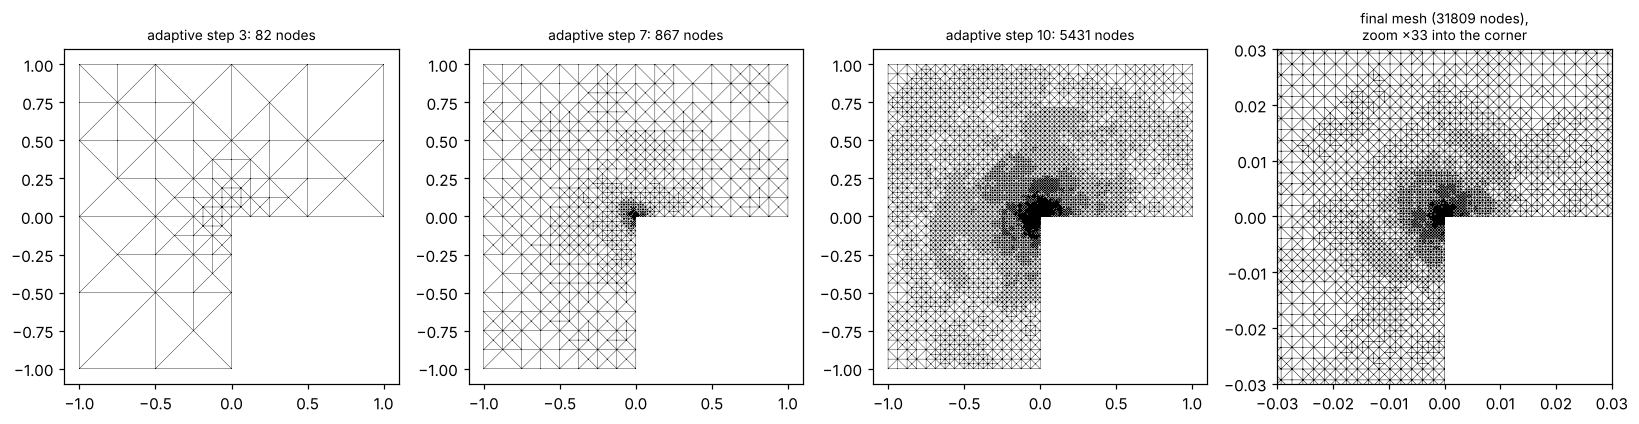

In [25]:
mesh = (nL, eL, bL, lL)
adaptive_L, snapshots = [], {}
for step in range(40):
    n_, e_, b_, l_ = mesh
    u_h = solve_L(n_, e_, b_)                                            # SOLVE
    eta2 = error_indicator(n_, e_, u_h, 1.0, b_, l_)                     # ESTIMATE
    adaptive_L.append((len(n_), fem_errors(n_, e_, u_h, u_sing, grad_sing)[1], np.sqrt(eta2.sum())))
    if step in (3, 7, 10):
        snapshots[step] = (n_, e_)
    if len(n_) > 20000:
        break
    mesh = refine_nvb(*mesh, doerfler_marking(eta2, 0.5))               # MARK + REFINE

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, (step, (n_, e_)) in zip(axes, snapshots.items()):
    ax.triplot(n_[:, 0], n_[:, 1], e_, lw=0.25, color="k")
    ax.set_aspect("equal"); ax.set_title(f"adaptive step {step}: {len(n_)} nodes", fontsize=9)
n_, e_ = mesh[0], mesh[1]                                   # final mesh, zoomed into the corner
axes[3].triplot(n_[:, 0], n_[:, 1], e_, lw=0.3, color="k")
axes[3].set_xlim(-0.03, 0.03); axes[3].set_ylim(-0.03, 0.03); axes[3].set_aspect("equal")
axes[3].set_title(f"final mesh ({len(n_)} nodes),\nzoom ×33 into the corner", fontsize=9)
plt.tight_layout(); plt.show()

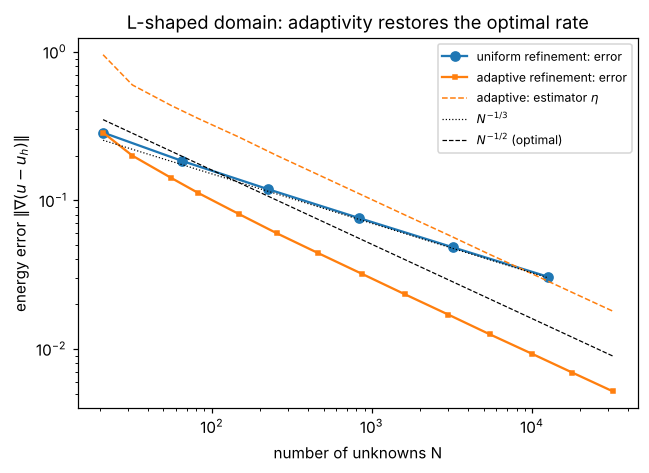

error 5.19e-03 with 31809 unknowns (adaptive) vs 3.06e-02 with 12545 (uniform)


In [26]:
NU, EU = np.array(uniform_L).T
NA, EA, ETA = np.array(adaptive_L).T
fig, ax = plt.subplots(figsize=(6, 4.4))
ax.loglog(NU, EU, "o-", label="uniform refinement: error")
ax.loglog(NA, EA, "s-", ms=3, label="adaptive refinement: error")
ax.loglog(NA, ETA, "--", lw=1, color="tab:orange", label=r"adaptive: estimator $\eta$")
ax.loglog(NU, 0.7 * NU ** (-1 / 3), "k:", lw=0.8, label=r"$N^{-1/3}$")
ax.loglog(NA, 1.6 * NA ** (-1 / 2), "k--", lw=0.8, label=r"$N^{-1/2}$ (optimal)")
ax.set_xlabel("number of unknowns N"); ax.set_ylabel(r"energy error $\|\nabla(u-u_h)\|$")
ax.legend(fontsize=8); ax.set_title("L-shaped domain: adaptivity restores the optimal rate")
plt.tight_layout(); plt.show()
print(f"error {EA[-1]:.2e} with {int(NA[-1])} unknowns (adaptive) vs {EU[-1]:.2e} with {int(NU[-1])} (uniform)")

Three things to take away:

* The adaptive meshes are **graded** towards the corner $(0,0)$, without our telling the algorithm where the corner is. The zoom shows that the grading continues across many length scales: the smallest triangles are several hundred times smaller than the largest.
* Adaptivity **restores the optimal rate** $N^{-1/2}$, the rate of a smooth problem.
* The estimator $\eta$ runs **parallel** to the true error. It overestimates by a roughly constant factor, so it can serve as a stopping criterion when the exact solution is unknown, which is always the case in practice.

## 9.4 Adaptive simulation of the room

Now we apply the same machinery to the room: heat source, insulated walls and Dirichlet windows. As the engineering **quantity of interest** we monitor the **mean room temperature**, and we compare uniform with adaptive refinement.

In [27]:
kind_room = lambda labels: np.where(labels == "window", "D", "N")

def mean_temperature(nodes, elems, T):
    _, area = gradients(nodes, elems)
    return np.sum(area * T[elems].mean(axis=1)) / area.sum()

def adaptive_room(mesh, max_nodes=100000, theta=0.5, show_at=3000):
    history, shown = [], None
    while True:
        n_, e_, b_, l_ = mesh
        s_ = solve_room(*mesh)                                                      # SOLVE
        eta2 = error_indicator(n_, e_, s_["T"], params["k_eff"], b_, kind_room(l_),  # ESTIMATE
                               f_elem=stove_source(n_, e_))
        history.append((len(n_), mean_temperature(n_, e_, s_["T"]), np.sqrt(eta2.sum())))
        if shown is None and len(n_) >= show_at:
            shown = mesh                                    # keep a mid-sized mesh for plotting
        if len(n_) > max_nodes:
            return mesh, shown, np.array(history)
        mesh = refine_nvb(*mesh, doerfler_marking(eta2, theta))                     # MARK + REFINE

t0 = time.perf_counter()
mesh_ad, mesh_show, hist_ad = adaptive_room((nodes0, elems0, bedges0, blabels0))
print(f"adaptive loop: {len(hist_ad)} steps, {time.perf_counter() - t0:.1f} s")

hist_un, mesh = [], (nodes0, elems0, bedges0, blabels0)
for level in range(5):
    s_ = solve_room(*mesh)
    hist_un.append((len(mesh[0]), mean_temperature(mesh[0], mesh[1], s_["T"])))
    mesh = refine_uniform(*mesh)
hist_un = np.array(hist_un)
T_ref = hist_ad[-1, 1]
print(f"reference mean temperature (finest adaptive mesh, {int(hist_ad[-1, 0])} nodes): {T_ref:.4f} °C")

adaptive loop: 14 steps, 8.5 s


reference mean temperature (finest adaptive mesh, 118797 nodes): 20.5742 °C


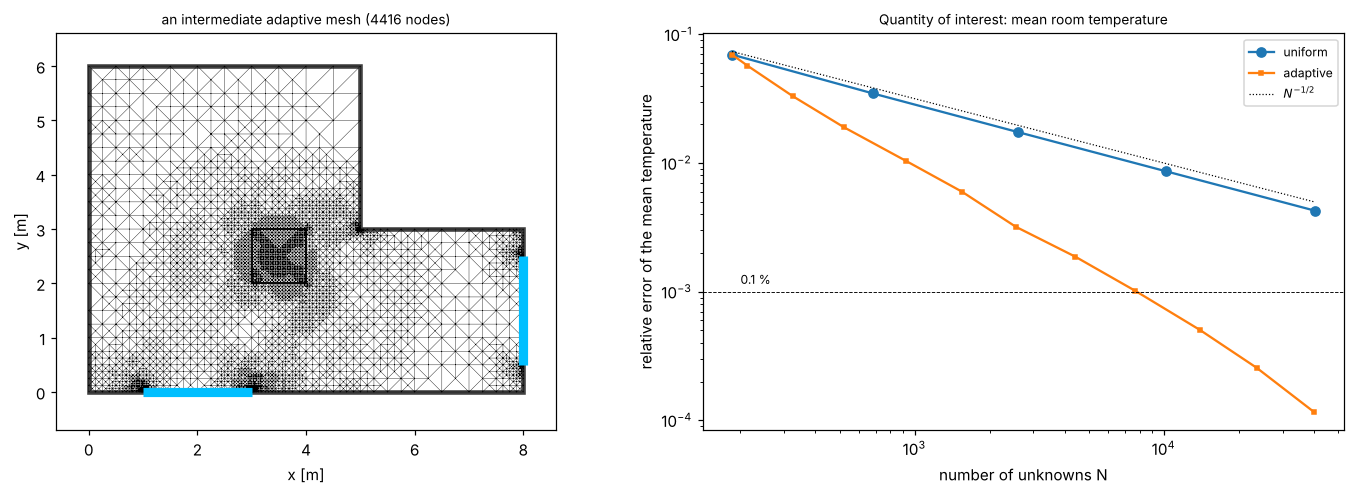

In [28]:
n_, e_, b_, l_ = mesh_show
fig = plt.figure(figsize=(13, 4.6))
ax = fig.add_subplot(1, 2, 1)
draw_floor_plan(ax, annotate=False, fill=False)
ax.triplot(n_[:, 0], n_[:, 1], e_, lw=0.25, color="k")
ax.set_title(f"an intermediate adaptive mesh ({len(n_)} nodes)", fontsize=9)
ax = fig.add_subplot(1, 2, 2)
ax.loglog(hist_un[:, 0], abs(hist_un[:, 1] - T_ref) / T_ref, "o-", label="uniform")
ax.loglog(hist_ad[:-2, 0], abs(hist_ad[:-2, 1] - T_ref) / T_ref, "s-", ms=3, label="adaptive")
ax.loglog(hist_un[:, 0], 1.0 * hist_un[:, 0] ** (-0.5), "k:", lw=0.8, label=r"$N^{-1/2}$")
ax.axhline(1e-3, color="k", lw=0.6, ls="--"); ax.text(200, 1.15e-3, "0.1 %", fontsize=8)
ax.set_xlabel("number of unknowns N"); ax.set_ylabel("relative error of the mean temperature")
ax.legend(fontsize=8); ax.set_title("Quantity of interest: mean room temperature", fontsize=9)
plt.tight_layout(); plt.show()

The adaptive algorithm puts small elements at

* the **four window edges**, the strongest singularities ($\beta = 1/2$),
* the **re-entrant corner** of the room $(5,3)$ ($\beta = 2/3$),
* the **stove region**, where the source term $f$ creates strong curvature of the temperature (the element residual $h_\tau^2\|f\|^2$),

and keeps the mesh coarse elsewhere, e.g. in the upper-left part of the room. The stove corners are not singular (Section 9.1): the refinement in the stove is driven by the source term, and it stays moderate compared with the extreme grading at the window edges.

On uniform meshes the mean temperature converges only like $N^{-1/2}$, slowed down by the window-edge singularities. Adaptivity reaches $0.1\%$ accuracy with fewer than ten thousand unknowns; extrapolating the uniform line, uniform refinement would need several hundred thousand. For 3D problems with millions of unknowns, such savings decide whether a simulation runs on a laptop or needs a cluster. (The last two adaptive values are left out of the error plot, because they are too close to the reference value to be meaningful.)

---
# Summary

| Step | What we did | Where |
|---|---|---|
| Model | energy balance + Fourier's law $\Rightarrow$ $-\nabla\cdot(k\nabla T)=f$ with a stove source, Dirichlet windows and insulated (Neumann) walls | Part 1 |
| Weak form | multiply by $v$, integrate by parts; Neumann becomes natural (no code!), Dirichlet stays essential | Part 3 |
| Discretise | P1 hat functions $\Rightarrow$ sparse SPD system $\mathbf K\mathbf T=\mathbf F$; the stove enters through the load vector | Parts 4–6 |
| Solve | eliminate Dirichlet nodes; reactions = heat loss per window | Part 7 |
| Check | energy balance to machine precision; manufactured solution with rates 2 and 1 | Parts 7, 8 |
| Understand | re-entrant corner $\Rightarrow r^{2/3}$, window edges $\Rightarrow r^{1/2}$ singularities $\Rightarrow$ slow uniform convergence | Part 9 |
| Improve | residual estimator + Dörfler marking + newest-vertex bisection $\Rightarrow$ optimal convergence | Part 9 |

**The big picture:** FEM turns a physical conservation law into linear algebra, in a way that respects geometry, discontinuous data and boundary physics. Its error theory tells us *how* the error decreases and *where* it comes from. All of this carries over to elasticity, electrostatics, groundwater flow, and beyond.

---
# Exercises

1. **Where to put the reading chair?** Find the region where $T\ge 20\,^\circ$C and at the same time $|\mathbf q|$ is small (little draught, in our crude model). Plot it.

2. **Better windows (Robin condition).** Double glazing does not keep the inner glass surface at outside temperature. Model a window by the heat transfer law $-k\,\partial_n T = \alpha\,(T - T_{\text{out}})$ with $\alpha = 2.8\,\mathrm{W/(m^2K)}$.
   * Redo the weak form: the window integral no longer vanishes. Show that you get the extra terms $\int_{\Gamma_R}\alpha\,T\,v\,ds$ on the left and $\int_{\Gamma_R}\alpha\,T_{\text{out}}\,v\,ds$ on the right.
   * Show that on a boundary edge $E$ this gives the edge matrix $\frac{\alpha|E|}{6}\begin{pmatrix}2&1\\1&2\end{pmatrix}$ and the edge load $\frac{\alpha T_{\text{out}}|E|}{2}\begin{pmatrix}1\\1\end{pmatrix}$, and implement them.
   * How much warmer does the room get at the same stove power? Do the window-edge singularities survive?

3. **Imperfect walls.** Real walls leak a little: use the same Robin law on the walls with $\alpha_{\text{wall}} = 0.3\,\mathrm{W/(m^2K)}$. Which fraction of the heat now leaves through the walls?

4. **Closing the windows.** Label both windows as walls and try to solve. What happens to the linear system, and why? Relate your observation to question 3 of Part 1 and to the Lax–Milgram discussion in Part 3.

5. **Where should the stove stand?** Try several grid-aligned stove positions. Which one minimises the temperature difference between the warmest and the coldest point of the room *outside* the stove?

6. **A different stove model.** Instead of a heat source, model the stove as a hole in the domain with a fixed surface temperature (Dirichlet). What happens at the stove corners now? (*Hint:* seen from the room, they are re-entrant corners.)

7. **(Advanced) Quadratic elements.** Implement P2 elements (6 nodes per triangle). Repeat the manufactured-solution test: which rates do you expect and observe? And for the L-shaped benchmark with uniform meshes?

8. **(Advanced) Condition number.** Estimate the condition number of $\mathbf K_{ff}$ for the uniform meshes (`scipy.sparse.linalg.eigsh` for the extreme eigenvalues). Confirm the theoretical growth $\kappa(\mathbf K)\sim h^{-2}$. What does this mean for iterative solvers?

---
# Further reading

* M. G. Larson, F. Bengzon: *The Finite Element Method: Theory, Implementation, and Applications*, Springer (2013). Very close in spirit to this notebook, with complete MATLAB codes.
* D. Braess: *Finite Elements: Theory, Fast Solvers, and Applications in Solid Mechanics*, Cambridge University Press. The classical textbook, including a posteriori error estimates.
* S. C. Brenner, L. R. Scott: *The Mathematical Theory of Finite Element Methods*, Springer. For the rigorous theory.
* P. Grisvard: *Elliptic Problems in Nonsmooth Domains*, Pitman (1985). The theory of corner and mixed-boundary singularities.
* W. Dörfler: *A convergent adaptive algorithm for Poisson's equation*, SIAM J. Numer. Anal. 33 (1996). The origin of Dörfler marking.
* S. Funken, D. Praetorius, P. Wissgott: *Efficient implementation of adaptive P1-FEM in Matlab*, Comput. Methods Appl. Math. 11 (2011). The refinement algorithm used here.
* Production software: [NGSolve](https://ngsolve.org), [FEniCSx](https://fenicsproject.org), [scikit-fem](https://github.com/kinnala/scikit-fem), [deal.II](https://www.dealii.org). After this notebook you will recognise every ingredient inside them.